# MVEmo: Music Emotion Recognition Multimodal (Global-Level Feature Fusion)

Notebook ini mengimplementasikan rancangan **E1–E7** (audio, lirik, MIDI, kombinasi bimodal, dan trimodal) dengan **concatenation + MLP**.
Semua ekstraksi embedding (MERT, XLM-R) dan training MLP dijalankan di **GPU lokal (CUDA)**.

Alur: inspeksi metadata -> manifest -> split berbasis song ID -> ekstraksi fitur (di-cache) -> training E1–E7 -> evaluasi.

**Catatan:** skema `mvemo_dataset.jsonl` dideteksi otomatis. Jika deteksi salah, isi `ID_KEY` / `LABEL_KEY` secara manual di cell konfigurasi.

## 0. Instalasi dependensi (jalankan sekali)

In [ ]:
# Jalankan sekali di environment proyek (.venv). Hapus tanda # untuk mengaktifkan.
# PyTorch dengan CUDA: sesuaikan dengan versi CUDA Anda, lihat https://pytorch.org/get-started/locally/
# Contoh (CUDA 12.1):
# %pip install torch torchaudio --index-url https://download.pytorch.org/whl/cu121

# %pip install transformers pandas numpy scikit-learn librosa soundfile pretty_midi matplotlib tqdm nnAudio

## 1. Konfigurasi

In [1]:
import json, re, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from transformers import AutoModel, AutoConfig, Wav2Vec2FeatureExtractor

warnings.filterwarnings("ignore")

# ---------- Path ----------
ROOT = Path("datasets/MVEmo")
META = ROOT / "mvemo_dataset.jsonl"
LYRICS_DIR = ROOT / "lyrics" / "lyrics"
AUDIO_DIR = ROOT / "music" / "music" / "audio"
MIDI_DIR = ROOT / "music" / "music" / "symbolic"

PROC = Path("processed")
EXP = Path("experiments")
for d in [PROC, PROC / "splits", PROC / "audio_embeddings", PROC / "lyrics_embeddings", PROC / "midi_features", EXP]:
    d.mkdir(parents=True, exist_ok=True)

# ---------- Metadata (None = deteksi otomatis) ----------
ID_KEY = None      # kolom ID lagu, contoh: "id"
LABEL_KEY = "static_emotion_category"   # kolom label emosi halus (dipetakan ke kuadran di bawah)
SAMPLED_CSV = Path("sampled_ids_per_emotion.csv")   # cadangan label jika kolom tidak ada di JSONL

# ---------- Pemetaan emosi -> kuadran (model circumplex, sesuai gambar) ----------
# Kata pada gambar: Q1 aroused/excited/happy; Q2 tense/angry/annoyed/distressed/frustrated;
# Q3 miserable/sad/depressed/droopy; Q4 pleased/content/satisfied/relaxed/sleepy.
# Kata yang TIDAK ada di gambar dipetakan mengikuti posisi circumplex Russell (1980); ubah jika perlu.
QUADRANT_MAP = {
    "Q1_Happy":   ["aroused", "excited", "happy", "delighted", "astonished"],
    "Q2_Angry":   ["tense", "angry", "annoyed", "distressed", "frustrated", "afraid", "alarmed"],
    "Q3_Sad":     ["miserable", "sad", "depressed", "droopy", "gloomy", "bored", "tired"],
    "Q4_Relaxed": ["pleased", "content", "satisfied", "relaxed", "sleepy", "calm", "serene", "glad"],
}
MAX_PER_QUADRANT = 200   # maksimal lagu per kuadran
SAMPLE_SEED = 42

# ---------- Model pretrained ----------
AUDIO_MODEL = "m-a-p/MERT-v1-95M"   # embedding audio 768-d, sample rate 24 kHz
TEXT_MODEL = "xlm-roberta-base"     # multilingual; ganti "bert-base-uncased"/"roberta-base" jika lirik 100% Inggris

# ---------- Ekstraksi ----------
AUDIO_SR = 24000
AUDIO_CHUNK_SEC = 30        # potongan audio untuk MERT
MAX_AUDIO_CHUNKS = 4        # maksimum potongan per lagu (dipilih merata sepanjang lagu)
AUDIO_BATCH = 4             # turunkan jika VRAM kurang
TEXT_MAX_TOKENS = 510       # token isi per chunk (+2 token spesial = 512)
MAX_TEXT_CHUNKS = 8
TEXT_BATCH = 16

# ---------- Cache ekstraksi & pembersihan lirik ----------
RESET_CACHE_ON_RUN = True        # True: hapus hasil ekstraksi lama sebelum sel ekstraksi dijalankan
DROP_CONSECUTIVE_DUPES = False   # True: hapus baris lirik duplikat berurutan

def reset_cache(*paths):
    """Hapus hanya hasil ekstraksi di processed/, bukan data asli di datasets/."""
    if not RESET_CACHE_ON_RUN:
        return
    for p in paths:
        p = Path(p)
        if p.is_dir():
            for f in p.glob("*.npy"):
                f.unlink()
        elif p.exists():
            p.unlink()
        print(f"Cache dihapus: {p}")

# ---------- Eksperimen ----------
SEED_SPLIT = 42
SEEDS = [42, 43, 44]        # seed training (mean +- std dilaporkan)
TEST_SIZE, VAL_SIZE = 0.15, 0.15
HP = dict(hidden=512, dropout=0.3, lr=1e-3, weight_decay=1e-2, batch_size=64, epochs=150, patience=20)

#------------ Muat Model--------



## 2. Pemeriksaan GPU

In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA tersedia:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU CUDA tidak terdeteksi. Pasang PyTorch build CUDA (lihat sel instalasi) dan pastikan driver NVIDIA aktif."
    )
DEVICE = torch.device("cuda:0")
props = torch.cuda.get_device_properties(0)
print(f"GPU: {props.name} | VRAM: {props.total_memory / 1024**3:.1f} GB | CUDA {torch.version.cuda}")
torch.backends.cudnn.benchmark = True

PyTorch: 2.14.1+cu130
CUDA tersedia: False


RuntimeError: GPU CUDA tidak terdeteksi. Pasang PyTorch build CUDA (lihat sel instalasi) dan pastikan driver NVIDIA aktif.

In [3]:
import sys, torch
print(sys.executable)   # harus menunjuk ke ...\mvemo\.venv\Scripts\python.exe
x = torch.zeros(1).cuda()
print(torch.cuda.mem_get_info())

d:\PELAJARAN\Semester 5\MACHINE LEARNING\Projek\mvemo\.venv\Scripts\python.exe
(5317328896, 6438780928)


## 3. Inspeksi metadata JSONL

In [4]:
records = []
with META.open("r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            records.append(json.loads(line))

print("Jumlah record:", len(records))
print("Top-level keys:", list(records[0].keys()))
for r in records[:3]:
    short = {k: (v[:80] + "...") if isinstance(v, str) and len(v) > 80 else v for k, v in r.items()}
    print(json.dumps(short, indent=2, ensure_ascii=False))

Jumlah record: 11764
Top-level keys: ['id', 'title', 'artist', 'genres', 'language', 'youtube_id', 'lyrics_file_name', 'video_file_name', 'music_audio_file_name', 'music_symbolic_file_name', 'static_emotion_category', 'static_emotion_intensity', 'dynamic_emotion_category', 'dynamic_emotion_intensity']
{
  "id": 0,
  "title": "Ultra Thizz",
  "artist": "Rustie",
  "genres": "[]",
  "language": "English",
  "youtube_id": "s4AqCrR_nAU",
  "lyrics_file_name": "lyrics/0.txt",
  "video_file_name": "Download from Youtube ID",
  "music_audio_file_name": "Download from Youtube ID",
  "music_symbolic_file_name": "music/symbolic/0.mid",
  "static_emotion_category": "glad",
  "static_emotion_intensity": 0.1,
  "dynamic_emotion_category": [
    {
      "time": 2.5,
      "category": "glad"
    },
    {
      "time": 3.0,
      "category": "glad"
    },
    {
      "time": 3.5,
      "category": "glad"
    },
    {
      "time": 4.0,
      "category": "glad"
    },
    {
      "time": 4.5,
      "ca

## 4. Manifest: pemetaan emosi -> kuadran Q1–Q4 dan sampling maks. 200 lagu per kuadran

In [5]:
meta = pd.json_normalize(records)
print("Kolom metadata:", list(meta.columns))

lyrics_ids = {p.stem for p in LYRICS_DIR.glob("*.txt")}
audio_ids = {p.stem for p in AUDIO_DIR.glob("*.wav")}
midi_ids = {p.stem for p in list(MIDI_DIR.glob("*.mid")) + list(MIDI_DIR.glob("*.midi"))}
print(f"File lirik={len(lyrics_ids)} | audio={len(audio_ids)} | MIDI={len(midi_ids)}")

def stem_of(v):
    return Path(str(v)).stem

# ---- deteksi kolom ID: kolom yang nilainya paling banyak cocok dengan nama file ----
if ID_KEY is None:
    best, best_score = None, 0.0
    for c in meta.columns:
        col = meta[c]
        if col.map(lambda x: isinstance(x, (list, dict))).any():
            continue
        score = col.map(lambda x: stem_of(x) in lyrics_ids).mean()
        if score > best_score:
            best, best_score = c, score
    print(f"Deteksi ID_KEY: {best} (kecocokan {best_score:.1%})")
    if best is None or best_score < 0.5:
        raise ValueError("ID_KEY tidak terdeteksi. Set ID_KEY secara manual di cell konfigurasi.")
    ID_KEY = best

# ---- label emosi halus (static_emotion_category) ----
if LABEL_KEY in meta.columns:
    man = pd.DataFrame({"song_id": meta[ID_KEY].map(stem_of), "emotion_category": meta[LABEL_KEY]})
else:
    print(f"Kolom {LABEL_KEY} tidak ada di JSONL; memakai label dari {SAMPLED_CSV}")
    lab = pd.read_csv(SAMPLED_CSV, dtype=str)
    man = pd.DataFrame({"song_id": lab.iloc[:, 0].map(stem_of), "emotion_category": lab.iloc[:, 1]})
man = man.dropna()
man["emotion_category"] = man.emotion_category.astype(str).str.strip().str.lower()
dup = man.song_id.duplicated().sum()
if dup:
    print(f"PERINGATAN: {dup} ID duplikat di metadata, dipertahankan yang pertama.")
    man = man.drop_duplicates("song_id", keep="first")

man["has_lyrics"] = man.song_id.isin(lyrics_ids)
man["has_audio"] = man.song_id.isin(audio_ids)
man["has_midi"] = man.song_id.isin(midi_ids)
man["lyrics_path"] = man.song_id.map(lambda s: str(LYRICS_DIR / f"{s}.txt"))
man["audio_path"] = man.song_id.map(lambda s: str(AUDIO_DIR / f"{s}.wav"))
def midi_path(s):
    for ext in (".mid", ".midi"):
        p = MIDI_DIR / f"{s}{ext}"
        if p.exists():
            return str(p)
    return str(MIDI_DIR / f"{s}.mid")
man["midi_path"] = man.song_id.map(midi_path)

# ---- petakan emosi halus -> kuadran ----
cat2quad = {c: q for q, cs in QUADRANT_MAP.items() for c in cs}
unmapped = sorted(set(man.emotion_category) - set(cat2quad))
if unmapped:
    print("PERINGATAN: kategori tidak terpetakan ke kuadran (dibuang):", unmapped)
man["label_name"] = man.emotion_category.map(cat2quad)
man = man.dropna(subset=["label_name"])

# ---- hanya lagu dengan 3 modalitas lengkap ----
n_before = len(man)
man = man[man.has_lyrics & man.has_audio & man.has_midi]
print(f"Lagu berlabel: {n_before} | lengkap (lirik+audio+MIDI): {len(man)}")
print("\nTersedia per kuadran sebelum sampling:")
print(man.label_name.value_counts().sort_index())

# ---- ambil maksimal MAX_PER_QUADRANT lagu per kuadran (acak, reproducible) ----
parts = [g.sample(n=min(len(g), MAX_PER_QUADRANT), random_state=SAMPLE_SEED) for _, g in man.groupby("label_name")]
man = pd.concat(parts).reset_index(drop=True)
for q, n in man.label_name.value_counts().sort_index().items():
    if n < MAX_PER_QUADRANT:
        print(f"CATATAN: {q} hanya punya {n} lagu (< {MAX_PER_QUADRANT})")

classes = sorted(man.label_name.unique())
label2idx = {c: i for i, c in enumerate(classes)}
man["label_idx"] = man.label_name.map(label2idx)
NUM_CLASSES = len(classes)
print("\nKelas:", label2idx)
print(pd.crosstab(man.label_name, man.emotion_category))
print(f"\nTotal sampel dipakai: {len(man)}")
man[["song_id", "emotion_category", "label_name"]].to_csv(PROC / "sampled_quadrant_ids.csv", index=False)

Kolom metadata: ['id', 'title', 'artist', 'genres', 'language', 'youtube_id', 'lyrics_file_name', 'video_file_name', 'music_audio_file_name', 'music_symbolic_file_name', 'static_emotion_category', 'static_emotion_intensity', 'dynamic_emotion_category', 'dynamic_emotion_intensity']
File lirik=11764 | audio=1013 | MIDI=11764
Deteksi ID_KEY: id (kecocokan 100.0%)
PERINGATAN: kategori tidak terpetakan ke kuadran (dibuang): ['at ease']
Lagu berlabel: 11761 | lengkap (lirik+audio+MIDI): 1013

Tersedia per kuadran sebelum sampling:
label_name
Q1_Happy      486
Q2_Angry      178
Q3_Sad        259
Q4_Relaxed     90
Name: count, dtype: int64
CATATAN: Q2_Angry hanya punya 178 lagu (< 200)
CATATAN: Q4_Relaxed hanya punya 90 lagu (< 200)

Kelas: {'Q1_Happy': 0, 'Q2_Angry': 1, 'Q3_Sad': 2, 'Q4_Relaxed': 3}
emotion_category  afraid  alarmed  angry  annoyed  aroused  astonished  bored  \
label_name                                                                      
Q1_Happy               0        0 

## 5. Split berbasis song ID (stratified, sekali untuk semua eksperimen)

In [6]:
from sklearn.model_selection import train_test_split

ids = man.song_id.values
y_all = man.label_idx.values
idx = np.arange(len(man))

# Stratifikasi gabungan label + ketersediaan audio agar subset audio tetap seimbang
strat = man.label_idx.astype(str) + "_" + man.has_audio.astype(int).astype(str)
if strat.value_counts().min() < 3:
    strat = man.label_idx

idx_trval, idx_te = train_test_split(idx, test_size=TEST_SIZE, stratify=strat.values[idx], random_state=SEED_SPLIT)
rel_val = VAL_SIZE / (1 - TEST_SIZE)
idx_tr, idx_va = train_test_split(idx_trval, test_size=rel_val, stratify=strat.values[idx_trval], random_state=SEED_SPLIT)

man["split"] = ""
man.loc[idx_tr, "split"] = "train"
man.loc[idx_va, "split"] = "validation"
man.loc[idx_te, "split"] = "test"

man.to_csv(PROC / "manifest.csv", index=False)
man[["song_id", "label_name", "label_idx"]].to_csv(PROC / "labels.csv", index=False)
for s in ["train", "validation", "test"]:
    man[man.split == s].to_csv(PROC / "splits" / f"{s}.csv", index=False)

print(pd.crosstab(man.split, man.label_name))
print("\nSubset audio lengkap per split:")
print(man[man.has_audio].groupby("split").size())

label_name  Q1_Happy  Q2_Angry  Q3_Sad  Q4_Relaxed
split                                             
test              30        27      30          14
train            140       124     140          62
validation        30        27      30          14

Subset audio lengkap per split:
split
test          101
train         466
validation    101
dtype: int64


## 6. Ekstraksi fitur audio (MERT, GPU) — resumable

In [7]:
import librosa
from transformers import AutoModel, Wav2Vec2FeatureExtractor
import transformers
print("transformers:", transformers.__version__)

AUD_DIR = PROC / "audio_embeddings"
reset_cache(AUD_DIR)

def pick_chunks(wav, sr, chunk_sec, max_chunks):
    n = int(chunk_sec * sr)
    if len(wav) <= n:
        return [wav]
    chunks = [wav[i:i + n] for i in range(0, len(wav) - n // 2, n)]
    chunks = [c for c in chunks if len(c) >= n // 2]
    if len(chunks) > max_chunks:
        sel = np.linspace(0, len(chunks) - 1, max_chunks).round().astype(int)
        chunks = [chunks[i] for i in sel]
    return chunks

todo = [s for s in man[man.has_audio].song_id if not (AUD_DIR / f"{s}.npy").exists()]
print(f"Audio perlu diproses: {len(todo)} (sisanya sudah ada di cache)")

if todo:
    fe = Wav2Vec2FeatureExtractor.from_pretrained(AUDIO_MODEL, trust_remote_code=True)
    mert = AutoModel.from_pretrained(AUDIO_MODEL, trust_remote_code=True).half().eval().to(DEVICE)
    assert fe.sampling_rate == AUDIO_SR

    # --- tangkap hidden states lewat hook (tidak bergantung versi transformers) ---
    captured = []
    layers = mert.encoder.layers

    def pre_hook(mod, args, kwargs):
        x = args[0] if len(args) > 0 else kwargs["hidden_states"]
        captured.append(x.detach())            # input layer-0 = hidden_states[0]

    def layer_hook(mod, args, output):
        o = output[0] if isinstance(output, (tuple, list)) else output
        captured.append(o.detach())            # keluaran tiap layer

    handles = [layers[0].register_forward_pre_hook(pre_hook, with_kwargs=True)]
    handles += [l.register_forward_hook(layer_hook) for l in layers]

    # --- tes cepat pada 1 lagu sebelum memproses semuanya ---
    test_wav, _ = librosa.load(str(AUDIO_DIR / f"{todo[0]}.wav"), sr=AUDIO_SR, mono=True, duration=10)
    captured.clear()
    inp = fe(test_wav, sampling_rate=AUDIO_SR, return_tensors="pt")
    inp = {k: v.to(DEVICE).half() if v.dtype.is_floating_point else v.to(DEVICE) for k, v in inp.items()}
    with torch.no_grad():
        mert(**inp)
    print("Jumlah hidden state tertangkap:", len(captured), "| bentuk:", tuple(captured[0].shape))
    assert len(captured) == len(layers) + 1, "hook tidak menangkap semua layer"

    failed_audio = []
    for sid in tqdm(todo, desc="MERT"):
        try:
            wav, _ = librosa.load(str(AUDIO_DIR / f"{sid}.wav"), sr=AUDIO_SR, mono=True)
            if len(wav) < AUDIO_SR:
                raise ValueError("audio terlalu pendek")
            chunk_embs = []
            for c in pick_chunks(wav, AUDIO_SR, AUDIO_CHUNK_SEC, MAX_AUDIO_CHUNKS):
                inp = fe(c, sampling_rate=AUDIO_SR, return_tensors="pt")
                inp = {k: v.to(DEVICE).half() if v.dtype.is_floating_point else v.to(DEVICE) for k, v in inp.items()}
                captured.clear()
                with torch.no_grad():
                    mert(**inp)
                h = torch.stack(captured, 0).squeeze(1).float()      # [13, T, 768]
                chunk_embs.append(h.mean(dim=1).mean(dim=0).cpu().numpy())
            np.save(AUD_DIR / f"{sid}.npy", np.mean(chunk_embs, axis=0).astype(np.float32))
        except Exception as e:
            failed_audio.append((sid, str(e)))
    print("Audio gagal:", len(failed_audio))
    if failed_audio:
        pd.DataFrame(failed_audio, columns=["song_id", "error"]).to_csv(PROC / "audio_failed.csv", index=False)

    for h_ in handles:
        h_.remove()
    del mert
    torch.cuda.empty_cache()

transformers: 5.22.2
Audio perlu diproses: 668 (sisanya sudah ada di cache)


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Jumlah hidden state tertangkap: 13 | bentuk: (1, 749, 768)


MERT:   0%|          | 0/668 [00:00<?, ?it/s]

Audio gagal: 0


## 7. Ekstraksi fitur lirik (XLM-R / BERT, GPU)

In [17]:
from transformers import AutoTokenizer

LYR_FILE = PROC / "lyrics_embeddings" / "lyrics.npz"
reset_cache(LYR_FILE)

TS_RE = re.compile(r"\[\d{1,3}:\d{1,2}(?:[.:]\d{1,3})?(?:[.:]\d{1,3})?\]")
META_RE = re.compile(r"\[(ti|ar|al|by|offset|re|ve|length)\s*:[^\]]*\]", re.I)
HEADER_RE = re.compile(r"^\s*\[00:00(?:[.:]\d+)?\]\s*[^\[\]]+?\s+[-\u2013\u2014]\s+.+$")
SECTION_RE = re.compile(
    r"^\s*[\[\(]\s*(?:(?:pre|post)[-\s]*)?"
    r"(?:chorus|chourus|verse|bridge|intro|outro|hook|refrain|interlude|instrumental|"
    r"break|drop|solo|adlib|spoken|repeat|ending|end)\b[^\]\)]*[\]\)]\s*$",
    re.I,
)

def clean_lyrics(t):
    # Bersihkan hanya di memori; file lirik asli tidak diubah.
    t = t.replace("\r\n", "\n").replace("\r", "\n")
    lines, seen_content = [], False
    for raw in t.split("\n"):
        line = raw.strip()

        if META_RE.search(line):
            line = META_RE.sub("", line).strip()
            if not line:
                continue

        # Header [00:00.00]Judul - Artis (hanya sebelum lirik pertama)
        if not seen_content and HEADER_RE.match(line):
            continue

        # Semua timestamp [mm:ss.xx]; teks lirik tetap disimpan
        line = TS_RE.sub("", line).strip()
        if not line:
            continue

        # Penanda bagian [Chorus], (Verse 1), [Pre-Chorus], [Bridge], dll.
        if SECTION_RE.match(line):
            continue

        if DROP_CONSECUTIVE_DUPES and lines and line == lines[-1]:
            continue

        seen_content = True
        lines.append(line)

    out = []
    for line in lines:
        line = re.sub(r"[ \t]+", " ", line).strip()
        if line:
            out.append(line)
    return "\n".join(out).strip()

cache_l = {}
if LYR_FILE.exists():
    z = np.load(LYR_FILE, allow_pickle=True)
    cache_l = dict(zip(z["ids"].astype(str), z["X"]))
todo_l = [s for s in man.song_id if s not in cache_l]
print(f"Lirik perlu diproses: {len(todo_l)} (sudah di cache: {len(cache_l)})")

if todo_l:
    tok = AutoTokenizer.from_pretrained(TEXT_MODEL)
    txt_model = AutoModel.from_pretrained(TEXT_MODEL).to(DEVICE).half().eval()

    # Sisakan ruang untuk 2 token khusus (<s> dan </s> / [CLS] dan [SEP])
    max_body = min(TEXT_MAX_TOKENS, tok.model_max_length - 2, 510)

    def add_special(ids):
        # prepare_for_model dihapus di transformers 5.x -> bangun manual
        try:
            return tok.build_inputs_with_special_tokens(ids)
        except Exception:
            cls_id = tok.cls_token_id if tok.cls_token_id is not None else tok.bos_token_id
            sep_id = tok.sep_token_id if tok.sep_token_id is not None else tok.eos_token_id
            return [cls_id] + ids + [sep_id]

    out_ids, out_vecs, empty_ids = [], [], []
    for sid in tqdm(todo_l, desc="Lirik"):
        text = clean_lyrics(Path(LYRICS_DIR / f"{sid}.txt").read_text(encoding="utf-8", errors="ignore"))
        if not text:
            empty_ids.append(sid)
            continue

        ids_ = tok(text, add_special_tokens=False, truncation=False)["input_ids"]
        chunks = [ids_[i:i + max_body] for i in range(0, len(ids_), max_body)][:MAX_TEXT_CHUNKS]
        chunks = [c for c in chunks if len(c) > 0]
        if not chunks:
            empty_ids.append(sid)
            continue
        feats = [add_special(c) for c in chunks]

        vecs = []
        for i in range(0, len(feats), TEXT_BATCH):
            b = feats[i:i + TEXT_BATCH]
            L = max(len(x) for x in b)
            pad = tok.pad_token_id if tok.pad_token_id is not None else 0
            input_ids = torch.tensor([x + [pad] * (L - len(x)) for x in b], device=DEVICE)
            mask = torch.tensor([[1] * len(x) + [0] * (L - len(x)) for x in b], device=DEVICE)
            with torch.no_grad():
                hs = txt_model(input_ids=input_ids, attention_mask=mask).last_hidden_state.float()
            m = mask.unsqueeze(-1).float()
            vecs.append(((hs * m).sum(1) / m.sum(1)).cpu().numpy())      # mean pooling per chunk
        out_ids.append(sid)
        out_vecs.append(np.concatenate(vecs, 0).mean(0))                  # rata-rata antar chunk

    cache_l.update(dict(zip(out_ids, out_vecs)))
    np.savez(LYR_FILE, ids=np.array(list(cache_l)), X=np.stack(list(cache_l.values())).astype(np.float32))
    print(f"Lirik terproses: {len(out_ids)} | kosong: {len(empty_ids)}")
    del txt_model
    torch.cuda.empty_cache()

Lirik perlu diproses: 62 (sudah di cache: 606)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Lirik:   0%|          | 0/62 [00:00<?, ?it/s]

Lirik terproses: 0 | kosong: 62


In [16]:
import collections

sizes = collections.Counter()
for sid in empty_ids:
    p = Path(LYRICS_DIR / f"{sid}.txt")
    raw = p.read_bytes()
    sizes["0 byte" if len(raw) == 0 else "ada isi tapi kosong setelah dibersihkan"] += 1

print(sizes)
print("\nContoh 5 file kosong:")
for sid in empty_ids[:5]:
    p = Path(LYRICS_DIR / f"{sid}.txt")
    print(sid, "| ukuran:", p.stat().st_size, "byte | isi mentah:", p.read_bytes()[:100])

Counter({'0 byte': 62})

Contoh 5 file kosong:
3848 | ukuran: 0 byte | isi mentah: b''
3904 | ukuran: 0 byte | isi mentah: b''
3637 | ukuran: 0 byte | isi mentah: b''
3885 | ukuran: 0 byte | isi mentah: b''
3903 | ukuran: 0 byte | isi mentah: b''


## 8. Ekstraksi fitur MIDI (pretty_midi)

In [10]:
import pretty_midi

MIDI_FILE = PROC / "midi_features" / "midi.npz"
reset_cache(MIDI_FILE)

FEATURE_NAMES = (
    ["duration", "log_n_notes", "log_note_density", "n_instruments", "n_drum_tracks",
     "pitch_mean", "pitch_std", "pitch_min", "pitch_max", "pitch_range",
     "dur_mean", "dur_std", "vel_mean", "vel_std", "vel_min", "vel_max",
     "ioi_mean", "ioi_std", "polyphony", "tempo_mean", "tempo_std", "n_tempo_changes",
     "n_time_sig_changes", "ts_numerator", "ts_denominator"]
    + [f"pc_{i}" for i in range(12)]
    + [f"prog_family_{i}" for i in range(16)]
)

def midi_features(path):
    pm = pretty_midi.PrettyMIDI(str(path))
    notes = [n for inst in pm.instruments if not inst.is_drum for n in inst.notes]
    if not notes:
        raise ValueError("tidak ada note")
    pitches = np.array([n.pitch for n in notes], dtype=float)
    durs = np.array([n.end - n.start for n in notes], dtype=float)
    vels = np.array([n.velocity for n in notes], dtype=float)
    starts = np.sort(np.array([n.start for n in notes]))
    total = max(pm.get_end_time(), 1e-6)
    ioi = np.diff(np.unique(np.round(starts, 4)))
    ioi = ioi if len(ioi) else np.array([0.0])
    uniq_onsets = max(len(np.unique(np.round(starts, 3))), 1)

    tempo_times, tempi = pm.get_tempo_changes()
    tempi = tempi if len(tempi) else np.array([120.0])

    pc = np.bincount((pitches % 12).astype(int), minlength=12).astype(float)
    pc = pc / pc.sum()

    fam = np.zeros(16)
    for inst in pm.instruments:
        key = 8 if inst.is_drum else min(inst.program // 8, 15)
        fam[key] += len(inst.notes)
    fam = fam / max(fam.sum(), 1)

    ts = pm.time_signature_changes
    ts_num = ts[0].numerator if ts else 4
    ts_den = ts[0].denominator if ts else 4

    vec = [
        total, np.log1p(len(notes)), np.log1p(len(notes) / total),
        len([i for i in pm.instruments if not i.is_drum]), len([i for i in pm.instruments if i.is_drum]),
        pitches.mean(), pitches.std(), pitches.min(), pitches.max(), pitches.max() - pitches.min(),
        durs.mean(), durs.std(), vels.mean(), vels.std(), vels.min(), vels.max(),
        ioi.mean(), ioi.std(), len(notes) / uniq_onsets, tempi.mean(), tempi.std(), len(tempi) - 1,
        len(ts), ts_num, ts_den,
    ] + pc.tolist() + fam.tolist()
    return np.nan_to_num(np.array(vec, dtype=np.float32))

cache_m = {}
if MIDI_FILE.exists():
    z = np.load(MIDI_FILE, allow_pickle=True)
    cache_m = dict(zip(z["ids"].astype(str), z["X"]))
todo_m = [(s, p) for s, p in zip(man.song_id, man.midi_path) if s not in cache_m]
print(f"MIDI perlu diproses: {len(todo_m)} (sudah di cache: {len(cache_m)})")

if todo_m:
    m_ids, m_vecs, m_failed = [], [], []
    for sid, p in tqdm(todo_m, desc="MIDI"):
        try:
            m_vecs.append(midi_features(p))
            m_ids.append(sid)
        except Exception as e:
            m_failed.append((sid, str(e)[:120]))
    cache_m.update(dict(zip(m_ids, m_vecs)))
    np.savez(MIDI_FILE, ids=np.array(list(cache_m)), X=np.stack(list(cache_m.values())))
    print(f"MIDI berhasil: {len(m_ids)} | gagal/kosong: {len(m_failed)}")
    if m_failed:
        pd.DataFrame(m_failed, columns=["song_id", "error"]).to_csv(PROC / "midi_failed.csv", index=False)

MIDI perlu diproses: 668 (sudah di cache: 0)


MIDI:   0%|          | 0/668 [00:00<?, ?it/s]

MIDI berhasil: 668 | gagal/kosong: 0


## 9. Muat fitur dan sejajarkan dengan manifest

In [11]:
def load_npz_aligned(path):
    z = np.load(path, allow_pickle=True)
    ids_, X = z["ids"].astype(str), z["X"]
    lut = dict(zip(ids_, range(len(ids_))))
    F = np.zeros((len(man), X.shape[1]), dtype=np.float32)
    avail = np.zeros(len(man), dtype=bool)
    for i, s in enumerate(man.song_id):
        j = lut.get(s)
        if j is not None:
            F[i] = X[j]
            avail[i] = True
    return F, avail

FEATS, AVAIL = {}, {}
FEATS["lyrics"], AVAIL["lyrics"] = load_npz_aligned(LYR_FILE)
FEATS["midi"], AVAIL["midi"] = load_npz_aligned(MIDI_FILE)

dim_a = 768
A = np.zeros((len(man), dim_a), dtype=np.float32)
a_av = np.zeros(len(man), dtype=bool)
for i, s in enumerate(man.song_id):
    p = AUD_DIR / f"{s}.npy"
    if p.exists():
        v = np.load(p)
        A[i, :len(v)] = v
        a_av[i] = True
FEATS["audio"], AVAIL["audio"] = A, a_av

for k in FEATS:
    print(f"{k:7s} dim={FEATS[k].shape[1]:4d} tersedia={AVAIL[k].sum():6d}")

COMMON = AVAIL["audio"] & AVAIL["lyrics"] & AVAIL["midi"]
print(f"\nIrisan lengkap (3 modalitas): {COMMON.sum()}")
print(man[COMMON].groupby("split").size())

lyrics  dim= 768 tersedia=   606
midi    dim=  53 tersedia=   668
audio   dim= 768 tersedia=   668

Irisan lengkap (3 modalitas): 606
split
test           89
train         427
validation     90
dtype: int64


## 10. Model dan fungsi training (GPU)

In [18]:
import torch.nn as nn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

class FusionMLP(nn.Module):
    def __init__(self, d_in, n_classes, hidden, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, n_classes),
        )
    def forward(self, x):
        return self.net(x)

def metrics(y, p):
    return dict(
        accuracy=accuracy_score(y, p),
        precision_macro=precision_score(y, p, average="macro", zero_division=0),
        recall_macro=recall_score(y, p, average="macro", zero_division=0),
        macro_f1=f1_score(y, p, average="macro", zero_division=0),
    )

@torch.no_grad()
def predict(model, X):
    model.eval()
    return model(X).argmax(1).cpu().numpy()

def run_experiment(mods, seed, subset_mask):
    """mods: list modalitas. subset_mask: boolean mask baris manifest yang dipakai."""
    set_seed(seed)
    sub = man[subset_mask]
    rows = {s: np.where(subset_mask & (man.split.values == s))[0] for s in ["train", "validation", "test"]}

    # standardisasi per modalitas HANYA dari data train
    Xs = {}
    for s, r in rows.items():
        Xs[s] = []
    for m in mods:
        mu = FEATS[m][rows["train"]].mean(0, keepdims=True)
        sd = FEATS[m][rows["train"]].std(0, keepdims=True) + 1e-6
        for s, r in rows.items():
            Xs[s].append((FEATS[m][r] - mu) / sd)
    T = {s: torch.tensor(np.concatenate(Xs[s], 1), dtype=torch.float32, device=DEVICE) for s in rows}
    Y = {s: torch.tensor(man.label_idx.values[r], dtype=torch.long, device=DEVICE) for s, r in rows.items()}

    counts = np.bincount(Y["train"].cpu().numpy(), minlength=NUM_CLASSES).astype(float)
    w = torch.tensor(counts.sum() / (NUM_CLASSES * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)

    model = FusionMLP(T["train"].shape[1], NUM_CLASSES, HP["hidden"], HP["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
    loss_fn = nn.CrossEntropyLoss(weight=w)

    n = len(T["train"])
    best_f1, best_state, bad = -1.0, None, 0
    for epoch in range(HP["epochs"]):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n, HP["batch_size"]):
            b = perm[i:i + HP["batch_size"]]
            if len(b) < 2:
                continue
            opt.zero_grad()
            loss = loss_fn(model(T["train"][b]), Y["train"][b])
            loss.backward()
            opt.step()
        f1 = f1_score(Y["validation"].cpu().numpy(), predict(model, T["validation"]), average="macro", zero_division=0)
        if f1 > best_f1:
            best_f1, bad = f1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= HP["patience"]:
                break
    model.load_state_dict(best_state)

    y_true = Y["test"].cpu().numpy()
    y_pred = predict(model, T["test"])
    res = metrics(y_true, y_pred)
    res.update(val_macro_f1=best_f1, epochs_run=epoch + 1,
               n_train=len(rows["train"]), n_val=len(rows["validation"]), n_test=len(rows["test"]))
    return res, y_true, y_pred

print("Fungsi training siap.")

Fungsi training siap.


## 11. Jalankan eksperimen E1–E7

`STRATEGY = "A"` (disarankan): semua eksperimen memakai **irisan lengkap** tiga modalitas, sehingga perbandingan apple-to-apple.
`STRATEGY = "B"`: setiap eksperimen memakai semua sampel yang tersedia untuk modalitasnya (jumlah sampel berbeda antar eksperimen).

In [19]:
STRATEGY = "A"   # "A" = common subset, "B" = maximum available

EXPERIMENTS = {
    "E1_audio": ["audio"],
    "E2_lyrics": ["lyrics"],
    "E3_midi": ["midi"],
    "E4_audio_lyrics": ["audio", "lyrics"],
    "E5_audio_midi": ["audio", "midi"],
    "E6_lyrics_midi": ["lyrics", "midi"],
    "E7_trimodal": ["audio", "lyrics", "midi"],
}

all_rows, preds = [], {}
t0 = time.time()
for name, mods in EXPERIMENTS.items():
    if STRATEGY == "A":
        mask = COMMON
    else:
        mask = np.logical_and.reduce([AVAIL[m] for m in mods])
    (EXP / name).mkdir(parents=True, exist_ok=True)
    for seed in SEEDS:
        res, yt, yp = run_experiment(mods, seed, mask)
        res.update(experiment=name, modalities="+".join(mods), seed=seed, strategy=STRATEGY)
        all_rows.append(res)
        preds[(name, seed)] = (yt, yp)
        print(f"{name:16s} seed={seed} acc={res['accuracy']:.4f} macroF1={res['macro_f1']:.4f} "
              f"(train={res['n_train']}, test={res['n_test']}, epoch={res['epochs_run']})")
    pd.DataFrame([r for r in all_rows if r["experiment"] == name]).to_json(
        EXP / name / "metrics.json", orient="records", indent=2)
print(f"\nSelesai dalam {(time.time() - t0) / 60:.1f} menit")

E1_audio         seed=42 acc=0.3708 macroF1=0.3292 (train=427, test=89, epoch=32)
E1_audio         seed=43 acc=0.2809 macroF1=0.2237 (train=427, test=89, epoch=50)
E1_audio         seed=44 acc=0.2809 macroF1=0.2606 (train=427, test=89, epoch=34)
E2_lyrics        seed=42 acc=0.3146 macroF1=0.2753 (train=427, test=89, epoch=22)
E2_lyrics        seed=43 acc=0.3258 macroF1=0.3108 (train=427, test=89, epoch=25)
E2_lyrics        seed=44 acc=0.2247 macroF1=0.1848 (train=427, test=89, epoch=23)
E3_midi          seed=42 acc=0.3596 macroF1=0.3573 (train=427, test=89, epoch=39)
E3_midi          seed=43 acc=0.3146 macroF1=0.2911 (train=427, test=89, epoch=29)
E3_midi          seed=44 acc=0.3371 macroF1=0.3235 (train=427, test=89, epoch=31)
E4_audio_lyrics  seed=42 acc=0.2921 macroF1=0.2198 (train=427, test=89, epoch=34)
E4_audio_lyrics  seed=43 acc=0.3708 macroF1=0.3276 (train=427, test=89, epoch=30)
E4_audio_lyrics  seed=44 acc=0.3146 macroF1=0.2776 (train=427, test=89, epoch=43)
E5_audio_midi   

## 12. Ringkasan hasil (mean ± std antar seed)

In [20]:
res_df = pd.DataFrame(all_rows)
metric_cols = ["accuracy", "precision_macro", "recall_macro", "macro_f1"]
summary = res_df.groupby(["experiment", "modalities"])[metric_cols].agg(["mean", "std"]).round(4)
summary["n_test"] = res_df.groupby(["experiment", "modalities"])["n_test"].first()
summary["n_train"] = res_df.groupby(["experiment", "modalities"])["n_train"].first()
res_df.to_csv(EXP / f"results_all_runs_strategy{STRATEGY}.csv", index=False)
summary.to_csv(EXP / f"results_summary_strategy{STRATEGY}.csv")
summary

accuracy         precision_macro          \
                                      mean     std            mean     std   
experiment      modalities                                                   
E1_audio        audio               0.3109  0.0519          0.2963  0.0971   
E2_lyrics       lyrics              0.2884  0.0554          0.2672  0.0685   
E3_midi         midi                0.3371  0.0225          0.3311  0.0371   
E4_audio_lyrics audio+lyrics        0.3258  0.0405          0.2700  0.0644   
E5_audio_midi   audio+midi          0.3521  0.0172          0.3353  0.0100   
E6_lyrics_midi  lyrics+midi         0.2996  0.0172          0.2503  0.0238   
E7_trimodal     audio+lyrics+midi   0.3296  0.0172          0.2993  0.0347   

                                  recall_macro         macro_f1          \
                                          mean     std     mean     std   
experiment      modalities                                                
E1_audio        audio                   0.2784  0.0466   0.2712  0.0536   
E2_lyrics       lyrics                  0.2619  0.0651   0.2569  0.0650   
E3_midi         midi                    0.3328  0.0395   0.3240  0.0331   
E4_audio_lyrics audio+lyrics            0.2854  0.0426   0.2750  0.0540   
E5_audio_midi   audio+midi              0.3230  0.0087   0.3220  0.0085   
E6_lyrics_midi  lyrics+midi             0.2703  0.0120   0.2521  0.0158   
E7_trimodal     audio+lyrics+midi       0.3013  0.0306   0.2971  0.0304   

                                  n_test n_train  
                                                  
experiment      modalities                        
E1_audio        audio                 89     427  
E2_lyrics       lyrics                89     427  
E3_midi         midi                  89     427  
E4_audio_lyrics audio+lyrics          89     427  
E5_audio_midi   audio+midi            89     427  
E6_lyrics_midi  lyrics+midi           89     427  
E7_trimodal     audio+lyrics+midi     89     427

## 13. Visualisasi: perbandingan Macro F1 dan confusion matrix

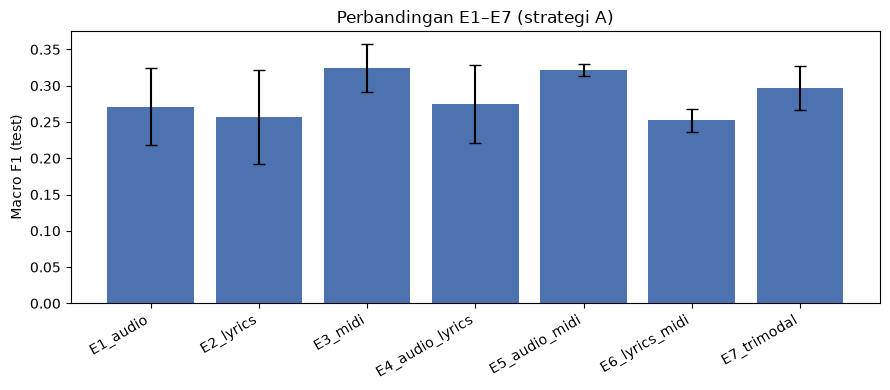

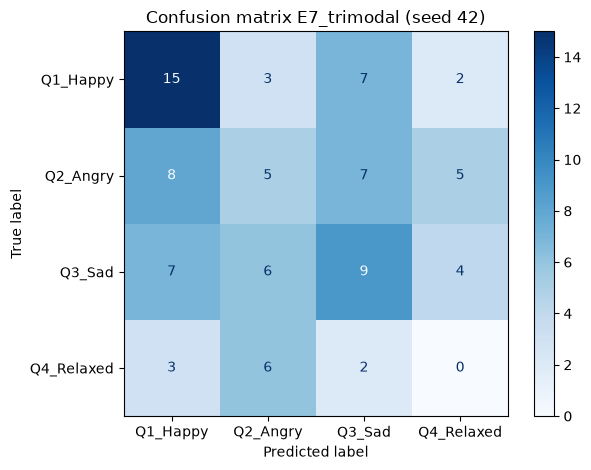

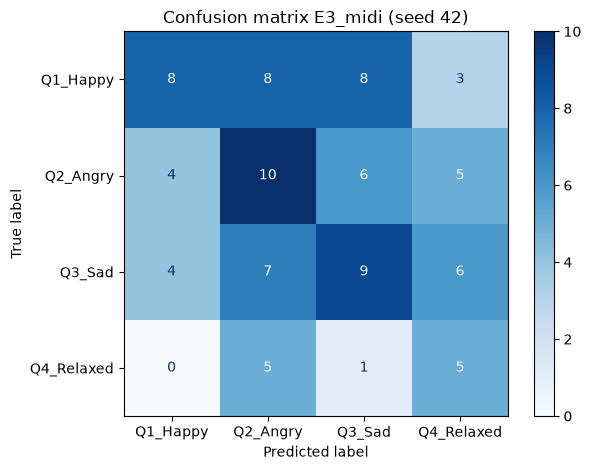

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

agg = res_df.groupby("experiment")["macro_f1"].agg(["mean", "std"]).reindex(list(EXPERIMENTS))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(agg.index, agg["mean"], yerr=agg["std"].fillna(0), capsize=4, color="#4C72B0")
ax.set_ylabel("Macro F1 (test)")
ax.set_title(f"Perbandingan E1–E7 (strategi {STRATEGY})")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(EXP / "macro_f1_comparison.png", dpi=150)
plt.show()

best_exp = agg["mean"].idxmax()
for name in ["E7_trimodal", best_exp]:
    yt, yp = preds[(name, SEEDS[0])]
    cm = confusion_matrix(yt, yp, labels=range(NUM_CLASSES))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion matrix {name} (seed {SEEDS[0]})")
    plt.tight_layout()
    plt.savefig(EXP / name / "confusion_matrix.png", dpi=150)
    plt.show()
    if name == best_exp == "E7_trimodal":
        break

## Catatan interpretasi

- Bandingkan **E7** dengan E1–E6 pada subset yang sama; selisih Macro F1 menunjukkan kontribusi tiap modalitas.
- Pastikan arti kelas (`classes` pada Bagian 4) sesuai dokumentasi MVEmo; jangan mengasumsikan makna kuadran dari urutan label.
- Periksa `processed/audio_failed.csv` dan `processed/midi_failed.csv` untuk sampel yang gagal diproses.
- Periksa potensi duplikasi lagu antar-split (versi berbeda dari lagu yang sama) sebelum melaporkan hasil akhir.
- Pengembangan lanjutan: gated fusion, cross-attention, dan segment-level alignment (Bagian 10 rancangan).